# ПР7. Случайный лес: классификация PHA и интерпретация признаков

**Задача:** сравнить одиночное дерево решений и случайный лес на задаче
классификации потенциально опасных астероидов (данные и схема — как в ПР-5),
проанализировать важность признаков тремя методами:
1. встроенная важность (impurity-based) случайного леса;
2. permutation importance;
3. SHAP.

Сравнение методов интерпретации — уровень C.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("../data/raw/dataset.csv", low_memory=False)

drop_cols = [
    "id", "spkid", "full_name", "pdes", "name", "prefix",
    "orbit_id", "equinox",
    "moid_ld", "epoch_mjd", "epoch_cal", "per_y", "tp_cal",
    "diameter_sigma", "diameter",
]
df_model = df.drop(columns=drop_cols)

clf_data = df_model.dropna(subset=["pha"]).copy()
X = clf_data.drop(columns=["pha"])
y = clf_data["pha"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include=["float64", "int64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["str", "object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Учебная выборка (та же схема, что в ПР-5): все Y + 50k N
y_train_arr = (y_train == "Y").values
idx_Y = np.where(y_train_arr)[0]
idx_N = np.where(~y_train_arr)[0]
rng = np.random.RandomState(42)
idx_sub = np.concatenate([idx_Y, rng.choice(idx_N, size=50_000, replace=False)])

X_sub = X_train_prep[idx_sub]
y_sub = y_train_arr[idx_sub].astype(int)
y_test_bin = (y_test == "Y").astype(int)

feature_names = preprocessor.get_feature_names_out()
print("Выборка:", X_sub.shape, "| признаков:", len(feature_names))

Выборка: (51653, 43) | признаков: 43


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_sub, y_sub)
pred_tree = tree.predict(X_test_prep)

forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest.fit(X_sub, y_sub)
pred_forest = forest.predict(X_test_prep)

def row(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_true, y_pred, zero_division=0), 4),
    }

comparison = pd.DataFrame([
    row("DecisionTree (single)", y_test_bin, pred_tree),
    row("RandomForest (n=100)", y_test_bin, pred_forest),
])
comparison

,model,accuracy,precision,recall,F1
0,DecisionTree (single),0.9998,0.9338,0.9903,0.9612
1,RandomForest (n=100),0.9998,0.9281,1.0000,0.9627


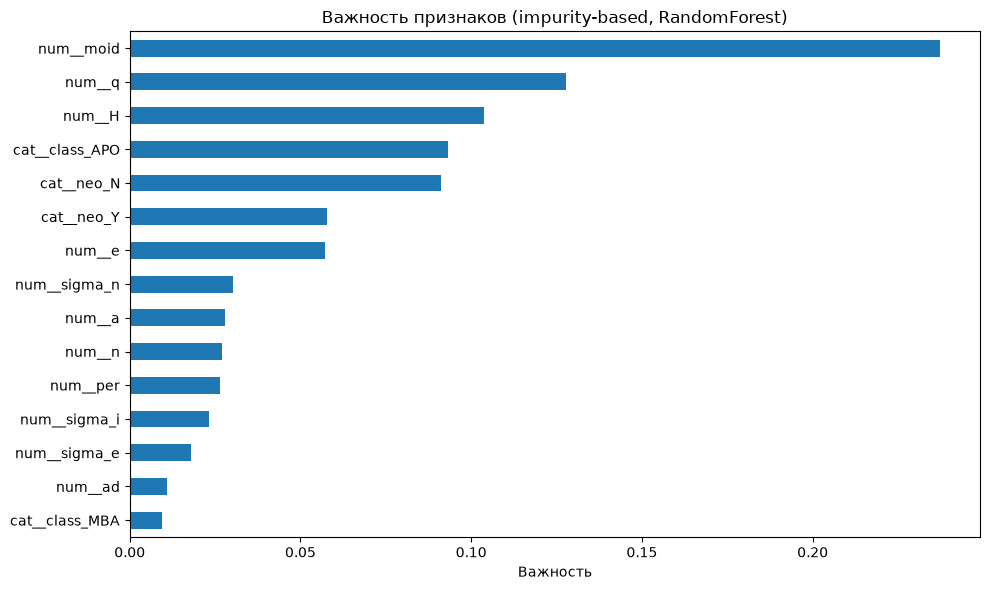

num__moid         0.237148
num__q            0.127722
num__H            0.103742
cat__class_APO    0.093154
cat__neo_N        0.091074
cat__neo_Y        0.057769
num__e            0.057208
num__sigma_n      0.030182
num__a            0.027833
num__n            0.026893
dtype: float64


In [3]:
# --- Важность признаков (встроенная, impurity-based) ---
importances = pd.Series(forest.feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top15.sort_values().plot.barh()
plt.title("Важность признаков (impurity-based, RandomForest)")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

print(top15.head(10))

In [4]:
# --- Мини-эксперимент: как n_estimators влияет на качество ---
from sklearn.metrics import f1_score as f1

scores = {}
for n in [10, 25, 50, 100, 200]:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_sub, y_sub)
    scores[n] = round(f1_score(y_test_bin, rf.predict(X_test_prep)), 4)

print(pd.Series(scores))

10     0.9448
25     0.9459
50     0.9614
100    0.9627
200    0.9650
dtype: float64


## Сравнение методов интерпретации (уровень C)

Встроенная важность (impurity-based) измеряет, насколько признак
уменьшал нечистоту узлов при обучении. Известные слабости:
- размывает важность между коррелированными признаками;
- завышает важность признаков с большим числом уникальных значений.

Permutation importance измеряет, насколько падает качество модели
на test, если значения признака перемешать — это честнее, т.к.
оценивает вклад на новых данных.

SHAP раскладывает конкретное предсказание на вклады признаков
(аддитивно) — показывает не только «что важно», но и «как признак
влияет на конкретный объект».

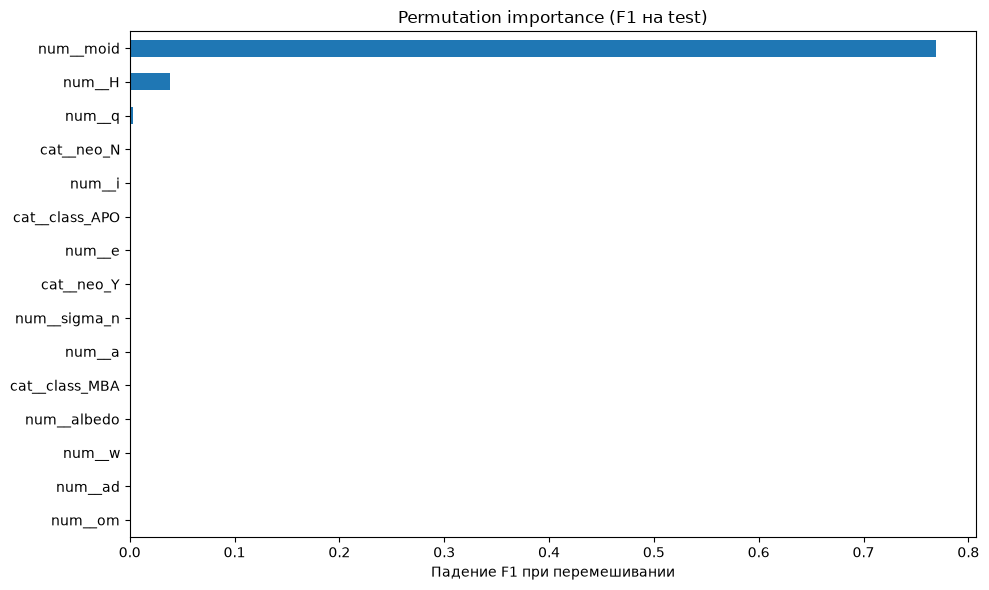

num__moid         0.769096
num__H            0.038340
num__q            0.003253
cat__neo_N        0.001617
cat__class_APO    0.000808
num__i            0.000808
num__e            0.000412
cat__neo_Y        0.000411
num__albedo       0.000404
num__a            0.000404
dtype: float64


In [5]:
from sklearn.inspection import permutation_importance

# Для скорости: подвыборка test (все Y + 3000 N)
idx_test_Y = np.where(y_test_bin.values == 1)[0]
idx_test_N = np.where(y_test_bin.values == 0)[0]
rng = np.random.RandomState(42)
test_sub = np.concatenate([idx_test_Y, rng.choice(idx_test_N, 3000, replace=False)])

perm = permutation_importance(
    forest, X_test_prep[test_sub], y_test_bin.values[test_sub],
    n_repeats=3, random_state=42, scoring="f1", n_jobs=-1
)

perm_sorted = pd.Series(perm.importances_mean, index=feature_names)
top15_perm = perm_sorted.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top15_perm.sort_values().plot.barh()
plt.title("Permutation importance (F1 на test)")
plt.xlabel("Падение F1 при перемешивании")
plt.tight_layout()
plt.show()

print(top15_perm.head(10))

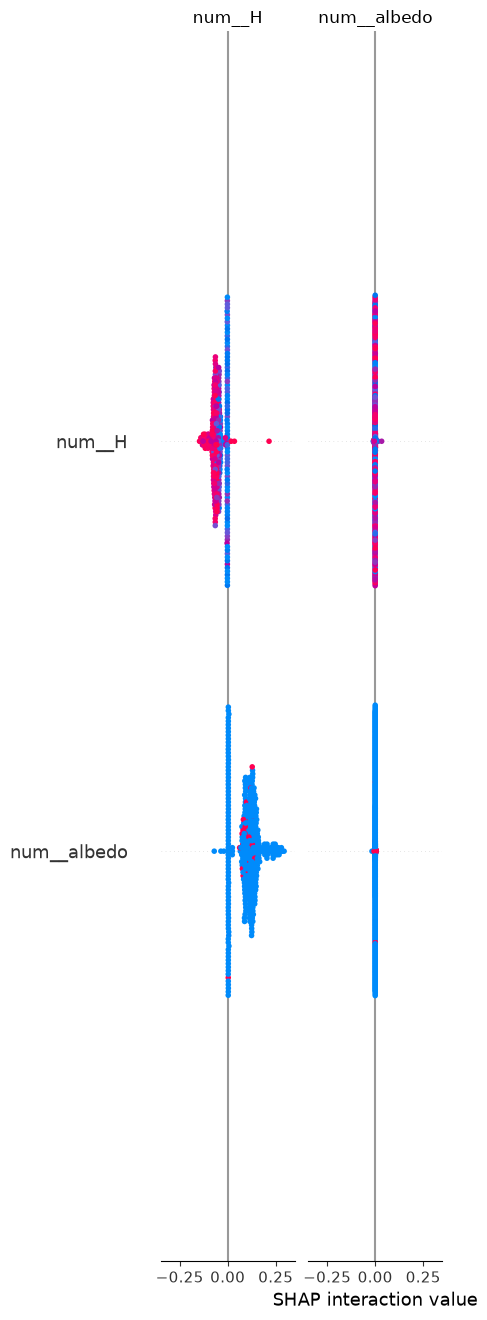

In [6]:
import shap

# TreeExplainer оптимален для леса; берём ~500 объектов для скорости
sample_shap = X_test_prep[test_sub[:500]]

explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(sample_shap)

# Для бинарной классификации shap_values может быть списком — берём класс 1 (Y)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(sv, sample_shap, feature_names=feature_names, max_display=15)

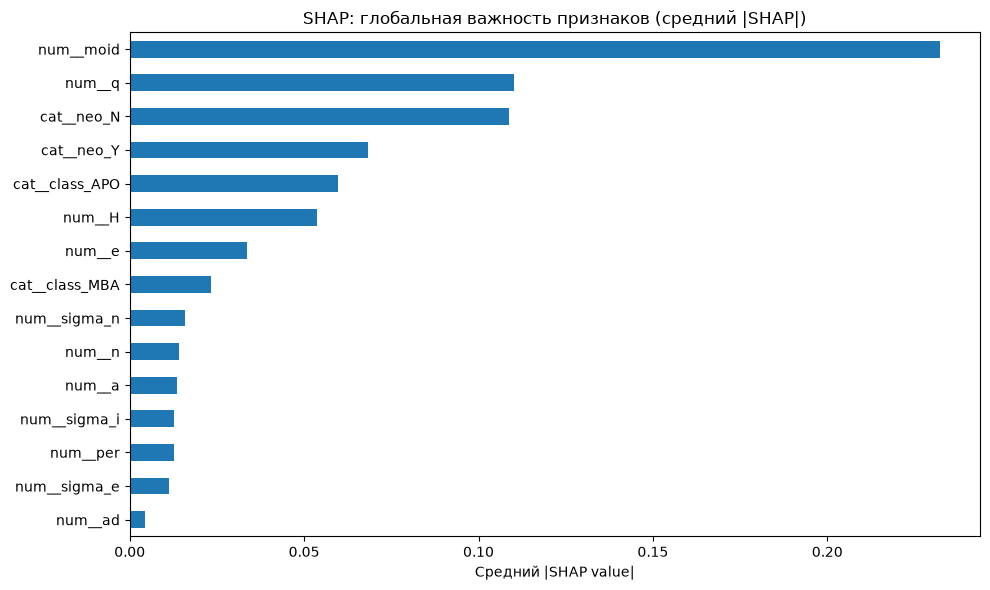

num__moid         0.232175
num__q            0.110141
cat__neo_N        0.108869
cat__neo_Y        0.068439
cat__class_APO    0.059706
num__H            0.053672
num__e            0.033537
cat__class_MBA    0.023331
num__sigma_n      0.015773
num__n            0.014089
dtype: float64


In [7]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sample_shap = X_test_prep[test_sub[:500]]
explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(sample_shap)

# Берём вклады для класса 1 ("Y") — в новых версиях shap_values может быть
# массивом вида (n, features, 2) — вырезаем последнюю ось
if isinstance(shap_values, list):
    sv = np.array(shap_values[1])
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

# Глобальная важность: средний |SHAP| по объектам
shap_importance = pd.Series(np.abs(sv).mean(axis=0), index=feature_names)
top_shap = shap_importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top_shap.sort_values().plot.barh()
plt.title("SHAP: глобальная важность признаков (средний |SHAP|)")
plt.xlabel("Средний |SHAP value|")
plt.tight_layout()
plt.show()

print(top_shap.head(10))

## Итог ПР-7: сравнение методов интерпретации

| Признак | Impurity | Permutation | SHAP |
|---|---|---|---|
| moid | 0.237 | **0.769** | 0.232 |
| q | 0.128 | 0.003 | 0.110 |
| neo_N/neo_Y | 0.149 | 0.002 | 0.177 |
| H | 0.104 | 0.038 | 0.054 |

**1. Все методы согласны:** главный признак — `moid` (минимальное расстояние
орбиты до орбиты Земли), что физически согласуется с определением PHA
и результатами ПР-2.

**2. Расхождения объяснимы.** Встроенная важность и SHAP распределяют вклад
между коррелированными признаками: `q` (перигелий) коррелирует с moid
на 0.9998 (ПР-2), и оба метода «делят» его важность между ними.
Permutation importance показывает вклад на test-данных: перемешивание `q`
почти не портит F1 (0.003), потому что ту же информацию несёт moid.
Это подтверждает предупреждение методички: impurity-based важность
завышает значимость коррелированных признаков.

**3. Что уникально у SHAP:** он не только ранжирует, но и показывает вклад
каждого признака в предсказание конкретного объекта (локальная интерпретация)
— первые два метода этого не умеют.

**4. Важность ≠ причинность.** Высокая важность moid отражает то, как
определён класс pha, а не «влияние» признака на опасность.

**Вывод проекта:** модель качественно (recall = 1.0) и интерпретируемо
(3 метода сходятся) решает задачу выявления потенциально опасных астероидов;
ключевой фактор — близость орбиты к орбите Земли (moid), вспомогательные —
перигелий, класс орбиты (APO) и яркость H.

In [8]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

# Сохраняем препроцессор и модель — демо будет грузить их из файлов
joblib.dump(preprocessor, "../models/preprocessor.joblib")
joblib.dump(forest, "../models/forest_pha.joblib")

print("Модель сохранена в models/")

Модель сохранена в models/


In [9]:
# Компактная версия леса для демо: 25 деревьев, качество почти то же,
# а файл весит в 4 раза меньше
forest_demo = RandomForestClassifier(n_estimators=25, random_state=42, n_jobs=-1)
forest_demo.fit(X_sub, y_sub)
joblib.dump(forest_demo, "../models/forest_pha.joblib")
print("Демо-модель сохранена")

Демо-модель сохранена
